#### Deep models - LSTM, GRU, CNN-LSTM, attention

Input = sliding window of the last L hours (scaled load + calendar features), target = load h hours after the last input hour.

Running on a laptop CPU, so to keep it around 2 hours:
- each model is tuned once per dataset at h=24 (8 Optuna trials, 4 epochs each), best settings reused for 1h and 168h
- window length L from 24, 48 or 72 hours (168 was too slow). For h=168 the last input hour is
  still the same hour one week before the target
- PJME: trained on the last 4 years of the train period (~35k hours, similar size to UCI train). val / test are the same as for the trees
- final models: 3 seeds, max 10 epochs with early stopping on val

In [1]:
import os
import json
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
tf.get_logger().setLevel("ERROR")
tf.autograph.set_verbosity(0)

os.makedirs("../figures", exist_ok=True)

In [2]:
HORIZONS = [1, 24, 168]
SEEDS = [0, 1, 2]
N_TRIALS = 8
TUNE_EPOCHS = 4
MAX_EPOCHS = 10
BATCH = 512
PJME_TRAIN_HOURS = 24 * 365 * 4

FEATURES = ["load", "hour_sin", "hour_cos", "month_sin", "month_cos", "dayofweek", "weekend", "holiday"]
MODELS = ["lstm", "gru", "cnn_lstm", "attention"]

os.makedirs("../results/predictions", exist_ok=True)

##### Data and windows

Windows are not stored, they are cut out with tf.gather for each batch (saves memory).
The val / test windows can look back into the previous split, same as the tree features.

In [3]:
def load_data(name):
    parts = [pd.read_parquet(f"../data/processed/{name}_{p}_scaled.parquet") for p in ["train", "val", "test"]]
    raw = [pd.read_parquet(f"../data/processed/{name}_{p}.parquet") for p in ["train", "val", "test"]]
    full = pd.concat(parts)
    actual = pd.concat(raw)["load"]
    n_tr, n_va = len(parts[0]), len(parts[1])

    scaler = joblib.load(f"../data/processed/{name}_scaler.pkl")
    lo, rng = scaler.data_min_[0], scaler.data_range_[0]   # load is the first column

    return {
        "X": tf.constant(full[FEATURES].values, dtype=tf.float32),
        "y": tf.constant(full["load"].values, dtype=tf.float32),
        "index": full.index,
        "actual": actual.values,
        "n_tr": n_tr, "n_va": n_va, "n": len(full),
        "lo": lo, "rng": rng,
    }


def target_rows(d, name, part, L, h):
    if part == "train":
        start = L - 1 + h
        if name == "pjme":
            start = max(start, d["n_tr"] - PJME_TRAIN_HOURS)
        return np.arange(start, d["n_tr"])
    if part == "val":
        return np.arange(d["n_tr"], d["n_tr"] + d["n_va"])
    return np.arange(d["n_tr"] + d["n_va"], d["n"])


def make_ds(d, rows, L, h, shuffle=False, seed=0):
    offsets = tf.range(-h - L + 1, -h + 1, dtype=tf.int64)

    def get_batch(t):
        x = tf.gather(d["X"], t[:, None] + offsets[None, :])
        y = tf.gather(d["y"], t)
        return x, y

    ds = tf.data.Dataset.from_tensor_slices(rows.astype("int64"))
    if shuffle:
        ds = ds.shuffle(len(rows), seed=seed)
    return ds.batch(BATCH).map(get_batch).prefetch(tf.data.AUTOTUNE)

In [4]:
d = load_data("pjme")
x, y = next(iter(make_ds(d, target_rows(d, "pjme", "train", 48, 24), 48, 24)))
print(x.shape, y.shape)
print("train targets:", len(target_rows(d, "pjme", "train", 48, 24)),
      "val:", len(target_rows(d, "pjme", "val", 48, 24)),
      "test:", len(target_rows(d, "pjme", "test", 48, 24)))

(512, 48, 8) (512,)
train targets: 35040 val: 21809 test: 21809


##### Models

Attention model is a simplified Temporal Fusion Transformer: LSTM encoder, gated residual connections
and multi-head attention where the query is the last time step. The attention scores show how much each
past hour is used.

In [5]:
def gate_add_norm(x, skip, units):
    # GLU gate + residual + layer norm (from TFT)
    g = layers.Multiply()([layers.Dense(units)(x), layers.Dense(units, activation="sigmoid")(x)])
    return layers.LayerNormalization()(layers.Add()([g, skip]))


def build_model(kind, p, L):
    inp = keras.Input((L, len(FEATURES)))

    if kind in ["lstm", "gru"]:
        rnn = layers.LSTM if kind == "lstm" else layers.GRU
        x = inp
        for i in range(p["layers"]):
            x = rnn(p["units"], return_sequences=i < p["layers"] - 1)(x)
            x = layers.Dropout(p["dropout"])(x)
        out = layers.Dense(1)(x)
        att = None

    elif kind == "cnn_lstm":
        x = layers.Conv1D(p["filters"], p["kernel"], padding="causal", activation="relu")(inp)
        x = layers.MaxPooling1D(2)(x)
        x = layers.LSTM(p["units"])(x)
        x = layers.Dropout(p["dropout"])(x)
        out = layers.Dense(1)(x)
        att = None

    else:
        u = p["units"]
        emb = layers.Dense(u)(inp)
        enc = layers.LSTM(u, return_sequences=True)(emb)
        enc = gate_add_norm(layers.Dropout(p["dropout"])(enc), emb, u)

        query = enc[:, -1:, :]
        a, att = layers.MultiHeadAttention(num_heads=p["heads"], key_dim=u // p["heads"], dropout=p["dropout"])(
            query, enc, return_attention_scores=True)
        x = gate_add_norm(layers.Dropout(p["dropout"])(a), query, u)

        # position-wise feed forward (GRN)
        f = layers.Dense(u, activation="elu")(x)
        f = layers.Dense(u)(f)
        x = gate_add_norm(f, x, u)
        out = layers.Dense(1)(layers.Flatten()(x))

    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(p["lr"]), loss="mse")
    att_model = keras.Model(inp, att) if att is not None else None
    return model, att_model

In [6]:
def suggest(trial, kind):
    p = {
        "L": trial.suggest_categorical("L", [24, 48, 72]),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),
        "units": trial.suggest_categorical("units", [32, 64, 128]),
    }
    if kind in ["lstm", "gru"]:
        p["layers"] = trial.suggest_int("layers", 1, 2)
    if kind == "cnn_lstm":
        p["filters"] = trial.suggest_categorical("filters", [32, 64])
        p["kernel"] = trial.suggest_categorical("kernel", [3, 5])
    if kind == "attention":
        p["heads"] = trial.suggest_categorical("heads", [2, 4])
    return p


def train(d, name, kind, p, h, epochs, seed):
    keras.utils.set_random_seed(seed)
    L = p["L"]
    model, att_model = build_model(kind, p, L)
    tr = make_ds(d, target_rows(d, name, "train", L, h), L, h, shuffle=True, seed=seed)
    va = make_ds(d, target_rows(d, name, "val", L, h), L, h)
    stop = keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)
    hist = model.fit(tr, validation_data=va, epochs=epochs, callbacks=[stop], verbose=0)
    return model, att_model, min(hist.history["val_loss"]), len(hist.history["loss"])


def predict(d, name, model, L, h, part="test"):
    rows = target_rows(d, name, part, L, h)
    pred = model.predict(make_ds(d, rows, L, h), verbose=0).ravel()
    return rows, pred * d["rng"] + d["lo"]


def scores(y, pred):
    return {
        "rmse": np.sqrt(mean_squared_error(y, pred)),
        "mae": mean_absolute_error(y, pred),
        "mape": mean_absolute_percentage_error(y, pred) * 100,
        "r2": r2_score(y, pred),
    }

##### Tuning (h=24)

In [7]:
best_params = {}
t0 = time.time()

for name in ["pjme", "uci"]:
    d = load_data(name)
    best_params[name] = {}
    for kind in MODELS:
        start = time.time()

        def objective(trial):
            p = suggest(trial, kind)
            _, _, val_loss, _ = train(d, name, kind, p, 24, TUNE_EPOCHS, seed=0)
            return val_loss

        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(objective, n_trials=N_TRIALS)
        best_params[name][kind] = study.best_params
        print(f"{name} {kind}: {study.best_params}  ({time.time() - start:.0f}s)")

print(f"tuning took {(time.time() - t0) / 60:.1f} min")

with open("../results/deep_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

pjme lstm: {'L': 48, 'lr': 0.0015751320499779737, 'dropout': 0.04680559213273095, 'units': 128, 'layers': 2}  (550s)


pjme gru: {'L': 48, 'lr': 0.0016409286730647919, 'dropout': 0.051157237106187456, 'units': 128, 'layers': 2}  (597s)


pjme cnn_lstm: {'L': 72, 'lr': 0.0035503048581283078, 'dropout': 0.28184968246925673, 'units': 128, 'filters': 64, 'kernel': 5}  (186s)


pjme attention: {'L': 48, 'lr': 0.00026587543983272726, 'dropout': 0.05454749016213018, 'units': 128, 'heads': 2}  (329s)


uci lstm: {'L': 72, 'lr': 0.004622589001020831, 'dropout': 0.06370173320348284, 'units': 128, 'layers': 2}  (289s)


uci gru: {'L': 72, 'lr': 0.004622589001020831, 'dropout': 0.06370173320348284, 'units': 128, 'layers': 2}  (336s)


uci cnn_lstm: {'L': 48, 'lr': 0.0015751320499779737, 'dropout': 0.04680559213273095, 'units': 128, 'filters': 64, 'kernel': 5}  (110s)


uci attention: {'L': 72, 'lr': 0.0005170191786366995, 'dropout': 0.08428035290621423, 'units': 128, 'heads': 4}  (198s)
tuning took 43.3 min


##### Final models - 3 horizons x 3 seeds

In [8]:
all_scores = []
attention = {}
t0 = time.time()

for name in ["pjme", "uci"]:
    d = load_data(name)
    for kind in MODELS:
        p = best_params[name][kind]
        for h in HORIZONS:
            start = time.time()
            preds = {}
            for seed in SEEDS:
                model, att_model, _, n_ep = train(d, name, kind, p, h, MAX_EPOCHS, seed)
                rows, pred = predict(d, name, model, p["L"], h)
                preds[f"seed_{seed}"] = pred

                if att_model is not None and seed == 0:
                    # mean attention over the test windows -> one weight per past hour
                    rows_te = target_rows(d, name, "test", p["L"], h)
                    a = att_model.predict(make_ds(d, rows_te, p["L"], h), verbose=0)
                    attention[f"{name}_h{h}"] = a.mean(axis=(0, 1, 2))

            y_true = d["actual"][rows]
            out = pd.DataFrame(preds, index=d["index"][rows])
            out.insert(0, "actual", y_true)
            out.to_parquet(f"../results/predictions/{name}_{kind}_h{h}.parquet")
            for s, pred in preds.items():
                all_scores.append({"dataset": name, "model": kind, "horizon": h, "seed": s, **scores(y_true, pred)})

            print(f"{name} {kind} h={h}: test rmse {np.mean([scores(y_true, v)['rmse'] for v in preds.values()]):.3f}"
                  f"  ({time.time() - start:.0f}s)")

print(f"final training took {(time.time() - t0) / 60:.1f} min")

pjme lstm h=1: test rmse 1153.673  (575s)


pjme lstm h=24: test rmse 2672.072  (464s)


pjme lstm h=168: test rmse 3782.367  (402s)


pjme gru h=1: test rmse 783.844  (606s)


pjme gru h=24: test rmse 2528.235  (521s)


pjme gru h=168: test rmse 3827.766  (432s)


... (14 outputs left out)

uci cnn_lstm h=168: test rmse 0.608  (48s)


uci attention h=1: test rmse 0.519  (390s)


uci attention h=24: test rmse 0.610  (384s)


uci attention h=168: test rmse 0.632  (379s)
final training took 151.3 min


In [9]:
scores_df = pd.DataFrame(all_scores)
scores_df.to_csv("../results/deep_scores.csv", index=False)

# attention weights: position 0 = oldest hour in the window, last = forecast origin
for k, w in attention.items():
    pd.DataFrame({"hours_before_origin": np.arange(len(w))[::-1], "weight": w}).to_csv(
        f"../results/attention_{k}.csv", index=False)

##### Results (test set, mean over seeds) - together with the baselines

In [10]:
base = pd.read_csv("../results/baseline_scores.csv")
both = pd.concat([base, scores_df])
summary = both.groupby(["dataset", "horizon", "model"])[["rmse", "mae", "mape", "r2"]].mean()
summary.round(3)

rmse       mae    mape     r2
dataset horizon model                                       
pjme    1       attention  1158.696   917.552   3.014  0.967
                cnn_lstm    877.154   686.211   2.233  0.981
                gru         783.844   607.132   1.958  0.985
                lstm       1153.673   883.154   2.839  0.968
                naive      4732.501  3431.189  10.689  0.460
                rf          394.078   278.487   0.893  0.996
                xgb         321.808   232.913   0.741  0.998
        24      attention  2750.334  2091.861   6.761  0.817
                cnn_lstm   2633.542  1993.872   6.367  0.833
                gru        2528.235  1883.024   5.953  0.846
                lstm       2672.072  1997.611   6.326  0.828
                naive      4732.501  3431.189  10.689  0.460
                rf         2473.246  1813.658   5.725  0.852
                xgb        2449.348  1808.696   5.714  0.855
        168     attention  3918.065  2994.236   9.562  0.629
                cnn_lstm   3848.586  2976.305   9.537  0.643
                gru        3827.766  2936.183   9.409  0.646
                lstm       3782.367  2904.797   9.296  0.655
                naive      4732.501  3431.189  10.689  0.460
                rf         3690.117  2788.780   8.832  0.672
                xgb        3686.814  2780.984   8.812  0.672
uci     1       attention     0.519     0.369  50.076  0.457
                cnn_lstm      0.507     0.370  52.018  0.484
                gru           0.492     0.356  50.271  0.513
                lstm          0.495     0.356  48.296  0.507
                naive         0.791     0.554  76.364 -0.257
                rf            0.461     0.317  42.809  0.573
                xgb           0.455     0.313  42.599  0.585
        24      attention     0.610     0.461  67.697  0.251
                cnn_lstm      0.595     0.441  63.384  0.288
                gru           0.591     0.438  61.704  0.298
                lstm          0.593     0.440  62.312  0.294
                naive         0.791     0.554  76.364 -0.257
                rf            0.573     0.421  62.984  0.341
                xgb           0.562     0.413  61.743  0.366
        168     attention     0.632     0.478  69.800  0.198
                cnn_lstm      0.608     0.459  68.049  0.258
                gru           0.595     0.445  65.918  0.288
                lstm          0.602     0.456  67.528  0.271
                naive         0.791     0.554  76.364 -0.257
                rf            0.587     0.435  65.266  0.309
                xgb           0.579     0.430  64.238  0.326

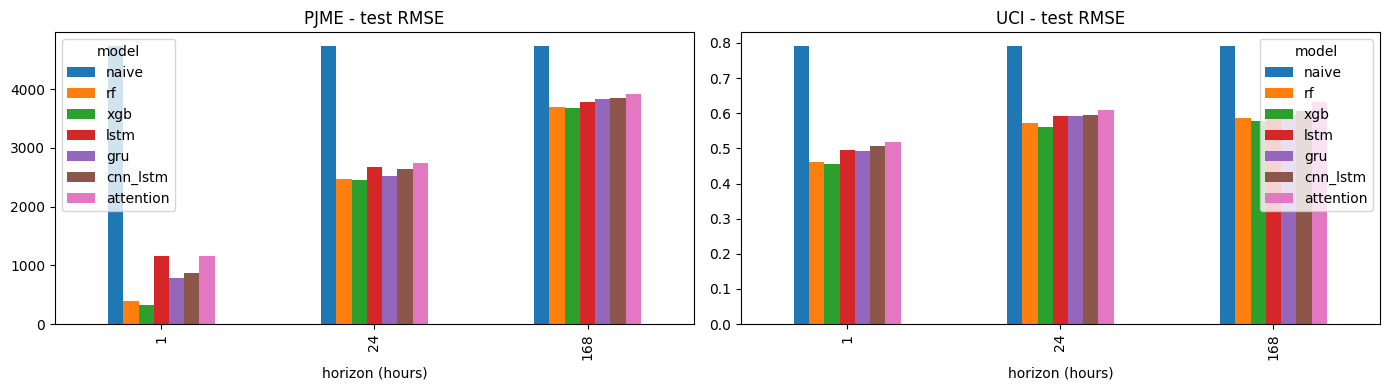

In [11]:
order = ["naive", "rf", "xgb", "lstm", "gru", "cnn_lstm", "attention"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, name in zip(ax, ["pjme", "uci"]):
    t = both[both["dataset"] == name].groupby(["horizon", "model"])["rmse"].mean().unstack()[order]
    t.plot(kind="bar", ax=a)
    a.set_title(name.upper() + " - test RMSE")
    a.set_xlabel("horizon (hours)")
plt.tight_layout()
plt.savefig("../figures/05_test_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- Tree models are best in every case. XGBoost has the lowest RMSE / MAE and highest R2 for both datasets and all horizons.
- Best deep model is mostly GRU (PJME 1h and 24h, UCI all horizons), LSTM is best of the deep models for PJME 168h.
- The gap is biggest at 1h for PJME (XGBoost 322 MW vs GRU 784 MW RMSE). At 24h and 168h the best deep model is only ~3% behind XGBoost.
- For UCI the deep models are also close to the trees (GRU R2 0.51 vs XGBoost 0.59 at 1h).
- Attention model is the weakest deep model everywhere.
- Deep models change more between seeds (PJME RMSE std up to ~170 MW for attention, trees < 3 MW).
- Keep in mind: the deep models got less tuning (8 trials at h=24 only) and less PJME training data (last 4 years)
  than the trees, so this comparison favours the trees.


In [12]:
both.groupby(["dataset", "horizon", "model"])["rmse"].std().unstack().round(3)

model            attention  cnn_lstm     gru    lstm  naive     rf    xgb
dataset horizon                                                          
pjme    1          171.747    69.981  35.484  88.742    NaN  0.235  1.600
        24         136.396    55.699  25.418  16.076    NaN  1.414  0.346
        168        161.942   117.965  91.611  44.725    NaN  1.979  2.308
uci     1            0.012     0.000   0.002   0.005    NaN  0.000  0.000
        24           0.003     0.008   0.004   0.006    NaN  0.000  0.001
        168          0.008     0.005   0.003   0.005    NaN  0.001  0.001

##### Attention weights

Mean attention over the test windows, by how many hours before the forecast origin.

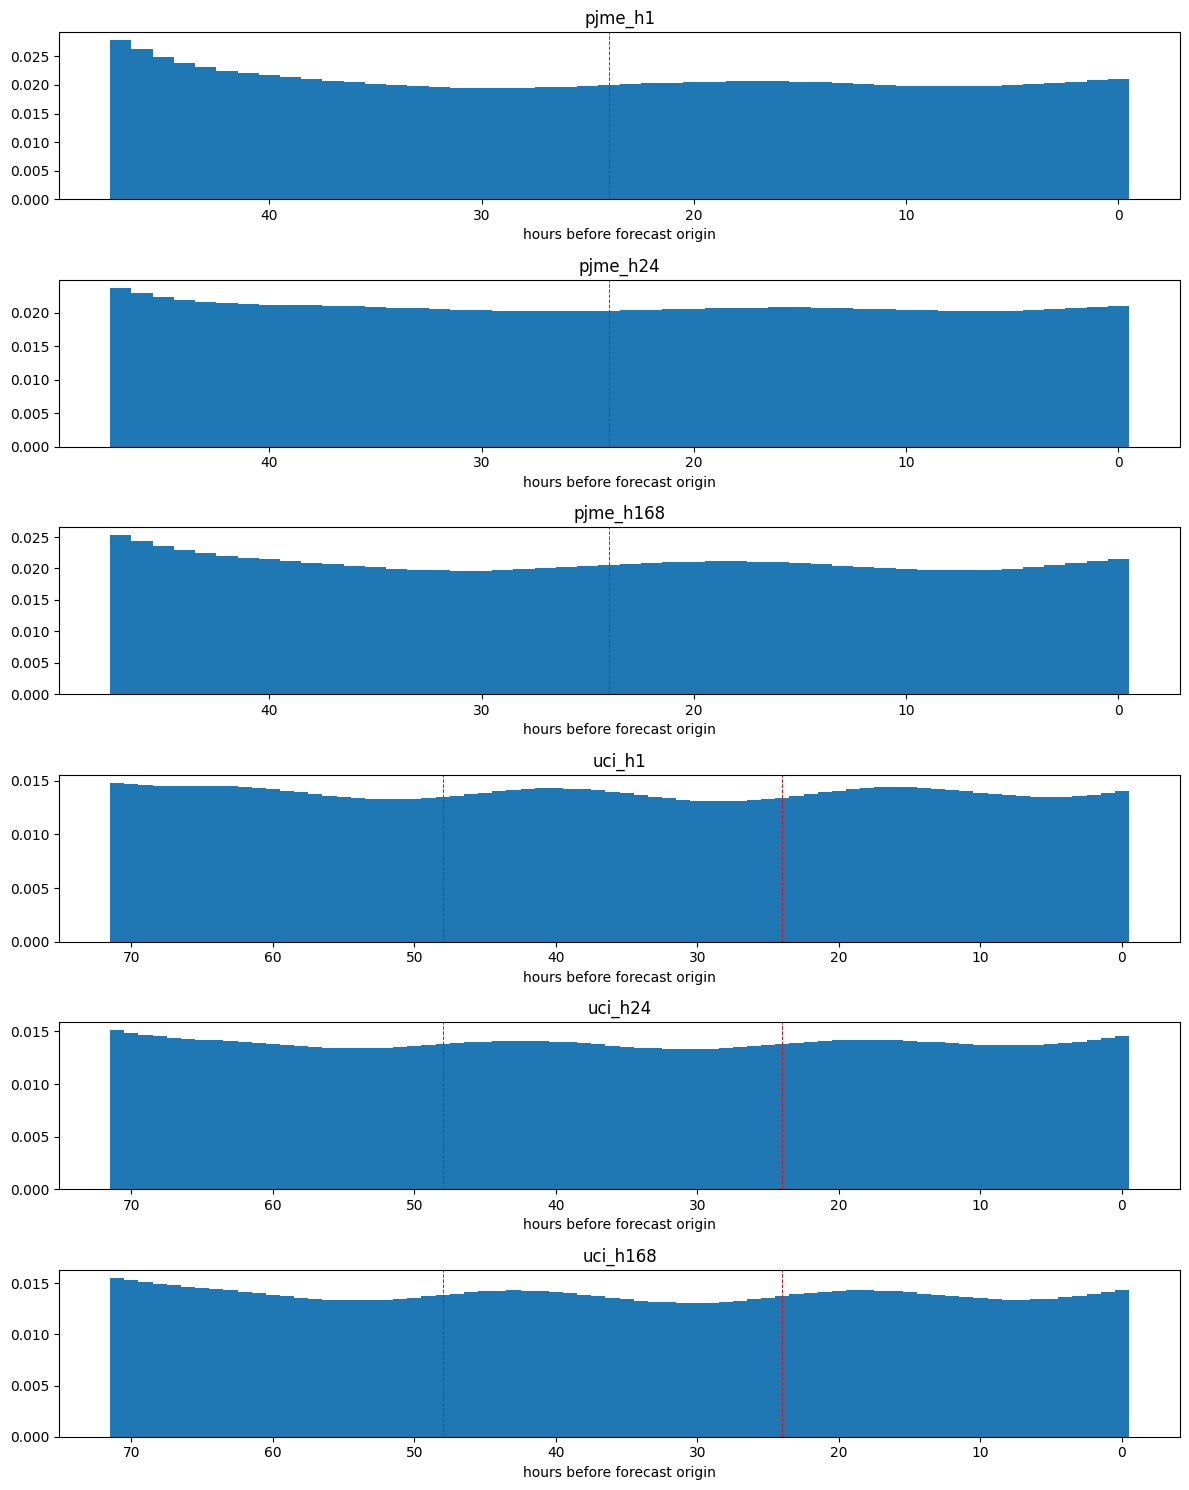

In [13]:
fig, ax = plt.subplots(len(attention), 1, figsize=(12, 2.5 * len(attention)))
for a, (k, w) in zip(np.atleast_1d(ax), attention.items()):
    hours_back = np.arange(len(w))[::-1]
    a.bar(hours_back, w, width=1)
    for lag in [24, 48, 168]:
        if lag < len(w):
            a.axvline(lag, color="red", ls="--", lw=0.7)
    a.invert_xaxis()
    a.set_title(k)
    a.set_xlabel("hours before forecast origin")
plt.tight_layout()
plt.savefig("../figures/05_attention_weights.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:
- The attention weights are almost flat (PJME max ~0.028 vs 1/48 = 0.021 if uniform, UCI ~0.015 vs 1/72 = 0.014).
- The largest weights are on the oldest hours of the window, not on the 24h cycle. With an LSTM encoder underneath, each
  step already carries information from the steps before, so the weights are not a clean "which hour matters" measure.
- So for RQ3 the attention weights alone don't show the daily / weekly cycles found in notebook 03.


##### Forecast vs actual - one test week, 24h ahead

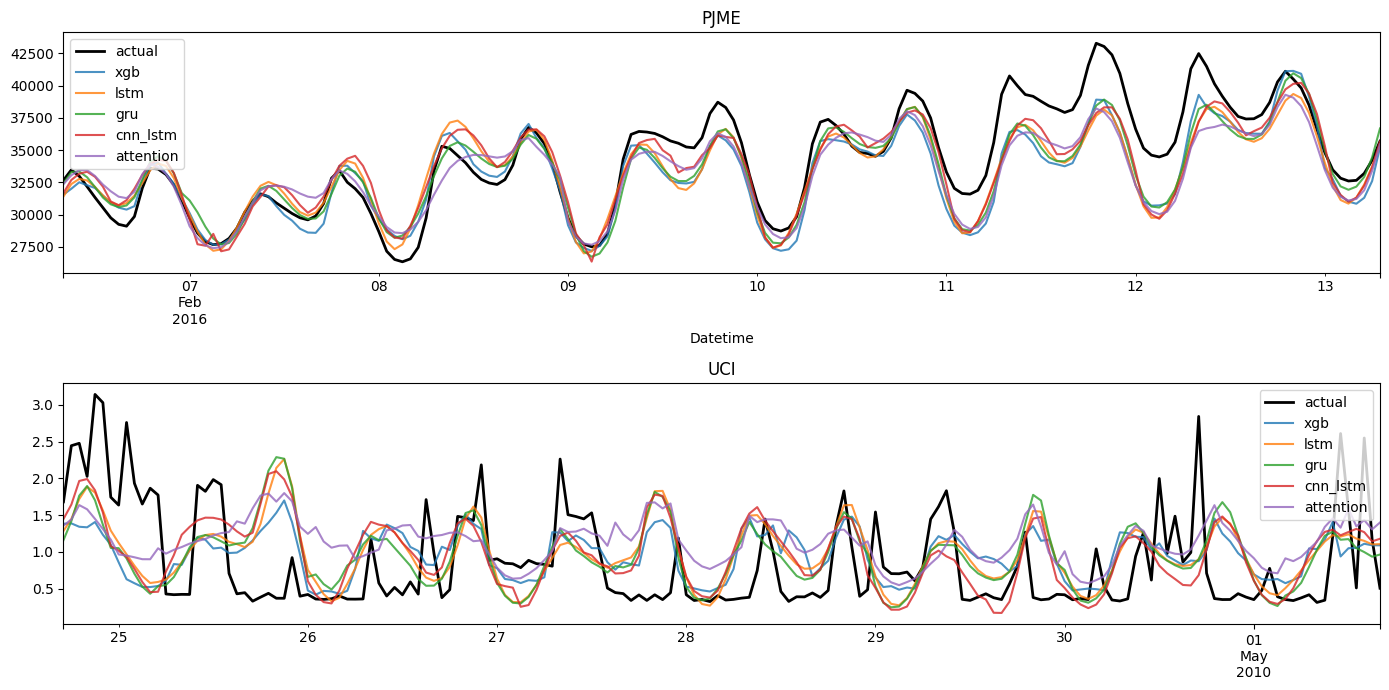

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(14, 7))
for a, name in zip(ax, ["pjme", "uci"]):
    week = slice(None, 24 * 7)
    first = True
    for model in ["xgb"] + MODELS:
        p = pd.read_parquet(f"../results/predictions/{name}_{model}_h24.parquet")
        if first:
            p["actual"].iloc[week].plot(ax=a, color="black", lw=2, label="actual")
            first = False
        p["seed_0"].iloc[week].plot(ax=a, label=model, alpha=0.8)
    a.set_title(name.upper())
    a.legend()
plt.tight_layout()
plt.savefig("../figures/05_forecast_week_24h.png", dpi=150, bbox_inches="tight")
plt.show()